In [2]:
import pandas as pd

In [4]:
import matplotlib.pyplot as plt

In [5]:
import seaborn as sns

In [7]:
df = pd.read_csv('train.csv')

In [8]:
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


## 1. Inspecting the Titanic Dataset

Before training the neural network, we must understand the available columns,
identify missing values and select useful passenger features.

The target variable is `Survived`.

In [9]:
# Display the size of the dataset.
print("Rows and columns:", df.shape)

# Display column names and their data types.
df.info()

# Count missing values in each column.
print("\nMissing values:")
print(df.isnull().sum())

# Count passengers in each target category.
print("\nSurvival counts:")
print(df["Survived"].value_counts())

Rows and columns: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embar

In [10]:
# Import tools for dividing the data into training and testing sets.
from sklearn.model_selection import train_test_split

# Import tools for preparing numerical and categorical columns.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Import TensorFlow for building the neural network.
import tensorflow as tf

# Import the neural-network model and layer types.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Import classification evaluation tools.
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Make the neural-network results more reproducible.
tf.random.set_seed(42)

print("Neural-network libraries imported successfully.")

Neural-network libraries imported successfully.


## 2. Selecting Features and the Target

We will use passenger class, sex, age, family information, fare and embarkation
port to predict survival.

We will not initially use passenger name, ticket number or cabin because they
require additional feature engineering.

In [11]:
# Select the passenger information supplied to the neural network.
feature_columns = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

# X contains the input features.
X = df[feature_columns]

# y contains the answer the network must learn to predict.
y = df["Survived"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Input shape: (891, 7)
Target shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


## 3. Splitting and Preprocessing the Data

The dataset is divided into training and testing sets.

- The training set teaches the neural network.
- The testing set checks its performance on passengers it has not seen before.

Numerical columns and categorical columns require different preparation.
Missing numerical values are replaced with the median. Missing categories are
replaced with the most common value.

In [12]:
# Divide the data into training and testing sets.
#
# 80% of the passengers will be used for training.
# 20% will be kept for final testing.
#
# stratify=y preserves approximately the same survival percentage
# in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training passengers:", X_train.shape[0])
print("Testing passengers:", X_test.shape[0])

Training passengers: 712
Testing passengers: 179


In [13]:
# Identify the numerical features.
numerical_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

# Identify the categorical features.
categorical_features = [
    "Sex",
    "Embarked"
]

# Prepare numerical columns.
numerical_pipeline = Pipeline([
    # Replace missing numerical values with the column median.
    ("imputer", SimpleImputer(strategy="median")),

    # Scale the values so large measurements such as Fare
    # do not dominate smaller measurements such as Pclass.
    ("scaler", StandardScaler())
])

# Prepare categorical columns.
categorical_pipeline = Pipeline([
    # Replace missing categories with the most common category.
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # Convert text categories into numerical columns.
    #
    # sparse_output=False returns an ordinary NumPy array,
    # which is suitable for the TensorFlow neural network.
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Apply the correct preparation process to each group of columns.
preprocessor = ColumnTransformer([
    ("numbers", numerical_pipeline, numerical_features),
    ("categories", categorical_pipeline, categorical_features)
])

# Learn the preprocessing rules from the training data
# and transform the training passengers.
X_train_prepared = preprocessor.fit_transform(X_train)

# Apply the same learned rules to the testing passengers.
#
# We use transform rather than fit_transform because the test set
# must not influence the preprocessing rules.
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared testing shape:", X_test_prepared.shape)

Prepared training shape: (712, 10)
Prepared testing shape: (179, 10)


## 4. Building the Neural Network

The neural network receives the ten prepared passenger features.

It contains:

1. An input layer that accepts the prepared features.
2. A hidden layer with 16 neurons.
3. A second hidden layer with 8 neurons.
4. An output layer with one neuron.

The hidden layers use the ReLU activation function.

The output layer uses the sigmoid activation function because this is a binary
classification problem. Sigmoid produces a value between 0 and 1, which can be
interpreted as the estimated probability of survival.

In [14]:
# Create a sequential neural network.
#
# Sequential means that information passes through each layer
# in order, from the input layer to the output layer.
model = Sequential([
    # Define how many prepared features enter the network.
    tf.keras.Input(shape=(X_train_prepared.shape[1],)),

    # First hidden layer containing 16 neurons.
    #
    # ReLU allows the network to learn more complicated
    # relationships between passenger information and survival.
    Dense(
        units=16,
        activation="relu"
    ),

    # Drop 20% of the neurons randomly during training.
    #
    # This can reduce overfitting, where the network memorises
    # the training passengers instead of learning general patterns.
    Dropout(0.20),

    # Second hidden layer containing 8 neurons.
    Dense(
        units=8,
        activation="relu"
    ),

    # Output layer containing one neuron.
    #
    # Sigmoid returns a probability between 0 and 1.
    Dense(
        units=1,
        activation="sigmoid"
    )
])

# Display the structure of the neural network.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Configuring the Neural Network

Before training, the model must be configured.

Binary cross-entropy measures the difference between the correct survival
answer and the probability predicted by the network.

The Adam optimiser adjusts the network's weights to reduce this error.

Accuracy measures the proportion of passengers classified correctly.

In [15]:
# Configure the neural network before training.
model.compile(
    # Adam controls how the model updates its weights.
    optimizer="adam",

    # Binary cross-entropy is appropriate because the target
    # contains two classes: 0 and 1.
    loss="binary_crossentropy",

    # Track classification accuracy during training.
    metrics=["accuracy"]
)

print("Neural network configured successfully.")

Neural network configured successfully.


## 6. Training the Neural Network

The neural network will study the prepared training passengers repeatedly.

One complete pass through the training data is called an epoch.

A validation set is kept separate during training so we can check whether the
network performs well on passengers it is not currently learning from.

Early stopping prevents unnecessary training when the validation loss stops
improving.

In [16]:
# Import EarlyStopping.
#
# Early stopping ends training when the model stops improving
# on the validation passengers.
from tensorflow.keras.callbacks import EarlyStopping

# Configure early stopping.
early_stopping = EarlyStopping(
    # Watch the validation loss after every epoch.
    monitor="val_loss",

    # Stop after ten epochs without an improvement.
    patience=10,

    # Return to the weights from the best training epoch.
    restore_best_weights=True
)

# Train the neural network.
history = model.fit(
    # Prepared passenger features.
    X_train_prepared,

    # Correct survival answers.
    y_train,

    # Maximum number of complete passes through the data.
    epochs=100,

    # Number of passengers processed before updating the weights.
    batch_size=32,

    # Keep 20% of the training data for validation.
    validation_split=0.20,

    # Use the early-stopping instructions defined above.
    callbacks=[early_stopping],

    # Display the result of every epoch.
    verbose=1
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3849 - loss: 0.7973 - val_accuracy: 0.3916 - val_loss: 0.7518
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4200 - loss: 0.7525 - val_accuracy: 0.5105 - val_loss: 0.7234
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5395 - loss: 0.7213 - val_accuracy: 0.5874 - val_loss: 0.7021
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6098 - loss: 0.7011 - val_accuracy: 0.6294 - val_loss: 0.6879
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6397 - loss: 0.6844 - val_accuracy: 0.6294 - val_loss: 0.6749
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6661 - loss: 0.6782 - val_accuracy: 0.6783 - val_loss: 0.6619
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6942 - loss: 0.6629 - val_accuracy: 0.6923 - val_loss: 0.6478
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6766 - loss: 0.6505 - val_accuracy: 0.7063 - v

In [17]:
# Find the number of epochs actually completed.
epochs_completed = len(history.history["loss"])

# Find the best validation accuracy achieved.
best_validation_accuracy = max(
    history.history["val_accuracy"]
)

print("Epochs completed:", epochs_completed)
print(
    "Best validation accuracy:",
    f"{best_validation_accuracy:.2%}"
)

Epochs completed: 37
Best validation accuracy: 82.52%


## 7. Visualising the Training History

The training history records the loss and accuracy after every epoch.

- Loss measures the size of the model's prediction errors.
- Accuracy measures the proportion of correct classifications.
- Training results come from passengers used to update the model.
- Validation results come from passengers not used for weight updates.

A large gap between training and validation performance can indicate
overfitting.

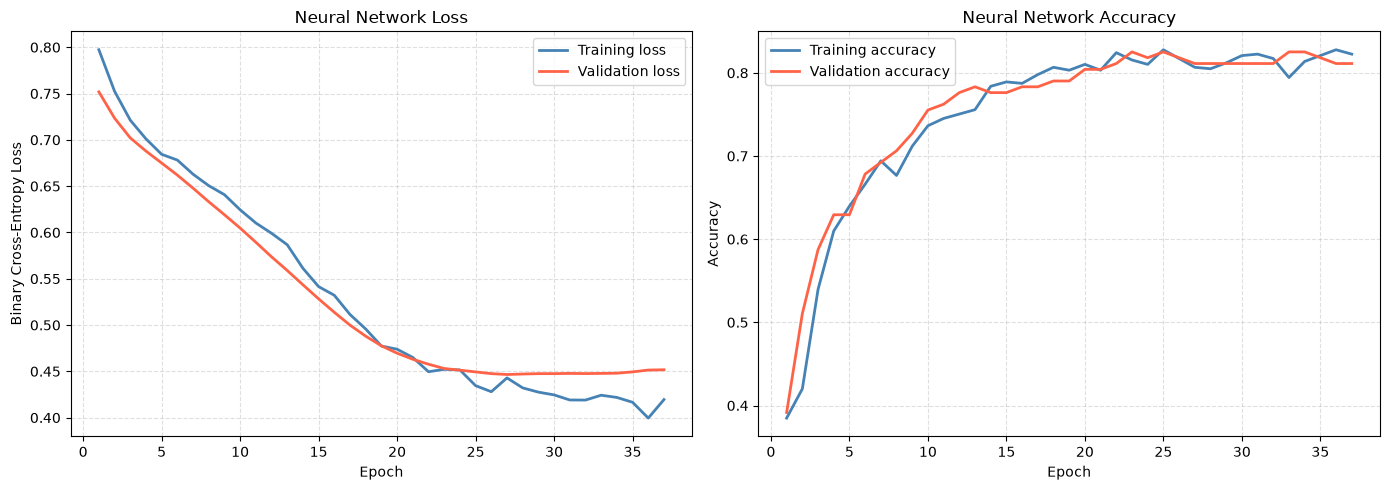

In [18]:
# Create epoch numbers starting at 1.
epoch_numbers = range(
    1,
    len(history.history["loss"]) + 1
)

# Create one figure containing two graphs.
figure, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# ---------------------------------------------------------
# Graph 1: Training and validation loss
# ---------------------------------------------------------

axes[0].plot(
    epoch_numbers,
    history.history["loss"],
    label="Training loss",
    color="steelblue",
    linewidth=2
)

axes[0].plot(
    epoch_numbers,
    history.history["val_loss"],
    label="Validation loss",
    color="tomato",
    linewidth=2
)

axes[0].set_title("Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(
    True,
    linestyle="--",
    alpha=0.4
)

# ---------------------------------------------------------
# Graph 2: Training and validation accuracy
# ---------------------------------------------------------

axes[1].plot(
    epoch_numbers,
    history.history["accuracy"],
    label="Training accuracy",
    color="steelblue",
    linewidth=2
)

axes[1].plot(
    epoch_numbers,
    history.history["val_accuracy"],
    label="Validation accuracy",
    color="tomato",
    linewidth=2
)

axes[1].set_title("Neural Network Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Prevent labels and titles from overlapping.
plt.tight_layout()

# Display both graphs.
plt.show()

## 8. Evaluating the Neural Network

The final model is evaluated using the test passengers that were not used
during training.

The network first returns a survival probability. We convert that probability
into a binary classification using a threshold of 0.5:

- Probability below 0.5 becomes class 0: did not survive.
- Probability of 0.5 or above becomes class 1: survived.

In [19]:
# Evaluate the model directly on the unseen test data.
test_loss, test_accuracy = model.evaluate(
    X_test_prepared,
    y_test,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.4603
Test accuracy: 79.89%


In [20]:
# Predict the probability of survival for every test passenger.
#
# The result for each passenger will be a value between 0 and 1.
survival_probabilities = model.predict(
    X_test_prepared,
    verbose=0
).flatten()

# Convert probabilities into classification answers.
#
# False becomes 0: did not survive.
# True becomes 1: survived.
survival_predictions = (
    survival_probabilities >= 0.5
).astype(int)

# Display the first ten probabilities and predictions.
prediction_results = pd.DataFrame({
    "Actual_Survival": y_test.to_numpy(),
    "Survival_Probability": survival_probabilities,
    "Predicted_Survival": survival_predictions
})

display(prediction_results.head(10).round(4))

,Actual_Survival,Survival_Probability,Predicted_Survival
0,0,0.1340,0
1,0,0.2572,0
2,1,0.2532,0
3,0,0.1339,0
4,1,0.6110,1
5,1,0.2771,0
6,1,0.7946,1
7,0,0.2276,0
8,0,0.3678,0
9,0,0.1309,0


## 9. Classification Performance

Accuracy alone does not explain every type of prediction error.

The classification report also includes:

- Precision: when the model predicts survival, how often it is correct.
- Recall: how many of the passengers who survived were correctly identified.
- F1-score: a balance between precision and recall.

In [21]:
# Calculate accuracy from the final class predictions.
final_accuracy = accuracy_score(
    y_test,
    survival_predictions
)

print(f"Final classification accuracy: {final_accuracy:.2%}")

# Display precision, recall and F1-score for both classes.
print("\nClassification report:")
print(
    classification_report(
        y_test,
        survival_predictions,
        target_names=[
            "Did not survive",
            "Survived"
        ]
    )
)

Final classification accuracy: 79.89%

Classification report:
                 precision    recall  f1-score   support

Did not survive       0.78      0.93      0.85       110
       Survived       0.84      0.59      0.69        69

       accuracy                           0.80       179
      macro avg       0.81      0.76      0.77       179
   weighted avg       0.80      0.80      0.79       179



## 10. Confusion Matrix

A confusion matrix separates the model's correct and incorrect classifications
into four groups:

- True negative: correctly predicted that a passenger did not survive.
- False positive: predicted survival when the passenger did not survive.
- False negative: predicted no survival when the passenger survived.
- True positive: correctly predicted that a passenger survived.

In [22]:
# Calculate the confusion matrix.
confusion = confusion_matrix(
    y_test,
    survival_predictions
)

# Display the four values as a labelled table.
confusion_table = pd.DataFrame(
    confusion,
    index=[
        "Actual: Did not survive",
        "Actual: Survived"
    ],
    columns=[
        "Predicted: Did not survive",
        "Predicted: Survived"
    ]
)

display(confusion_table)

,Predicted: Did not survive,Predicted: Survived
Actual: Did not survive,102,8
Actual: Survived,28,41


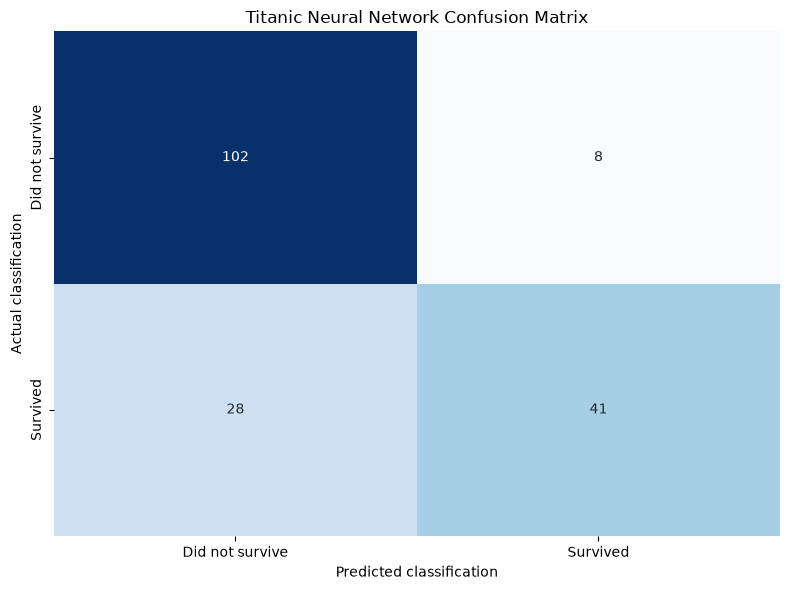

In [23]:
# Create a heatmap of the confusion matrix.
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        "Did not survive",
        "Survived"
    ],
    yticklabels=[
        "Did not survive",
        "Survived"
    ]
)

plt.title("Titanic Neural Network Confusion Matrix")
plt.xlabel("Predicted classification")
plt.ylabel("Actual classification")
plt.tight_layout()
plt.show()

In [24]:
# Extract the four confusion-matrix results.
true_negatives, false_positives, false_negatives, true_positives = (
    confusion.ravel()
)

print(
    "Correctly predicted did not survive:",
    true_negatives
)

print(
    "Incorrectly predicted survived:",
    false_positives
)

print(
    "Incorrectly predicted did not survive:",
    false_negatives
)

print(
    "Correctly predicted survived:",
    true_positives
)

Correctly predicted did not survive: 102
Incorrectly predicted survived: 8
Incorrectly predicted did not survive: 28
Correctly predicted survived: 41


## 11. Predicting the Separate Test Dataset

The separate `test.csv` file contains passengers without known survival
answers.

We apply the same preprocessing rules and trained neural network to estimate
each passenger's probability and predicted survival classification.

In [25]:
# Load the separate Titanic test dataset.
new_passengers = pd.read_csv("test.csv")

# Keep the passenger IDs for the final results file.
passenger_ids = new_passengers["PassengerId"]

# Select exactly the same features used during training.
new_passenger_features = new_passengers[feature_columns]

# Apply the preprocessing rules learned from train.csv.
#
# We use transform rather than fit_transform because we must not
# learn new preparation rules from this dataset.
new_passengers_prepared = preprocessor.transform(
    new_passenger_features
)

# Estimate each passenger's probability of survival.
new_survival_probabilities = model.predict(
    new_passengers_prepared,
    verbose=0
).flatten()

# Convert probabilities into binary classifications.
new_survival_predictions = (
    new_survival_probabilities >= 0.5
).astype(int)

# Create a detailed results table.
test_predictions = pd.DataFrame({
    "PassengerId": passenger_ids,
    "SurvivalProbability": new_survival_probabilities,
    "Survived": new_survival_predictions
})

display(test_predictions.head(10).round(4))

,PassengerId,SurvivalProbability,Survived
0,892,0.2331,0
1,893,0.2630,0
2,894,0.2338,0
3,895,0.1636,0
4,896,0.5323,1
5,897,0.1717,0
6,898,0.7284,1
7,899,0.2247,0
8,900,0.7598,1
9,901,0.1342,0


In [26]:
# Create the standard two-column submission format.
submission = test_predictions[
    ["PassengerId", "Survived"]
]

# Save the classifications inside the Week6 folder.
submission.to_csv(
    "titanic_neural_network_predictions.csv",
    index=False
)

print("Predictions saved successfully.")
print("Number of predictions:", len(submission))

Predictions saved successfully.
Number of predictions: 418


## Missing Values

The dataset contains missing values in three variables:

- `Age` contains 177 missing values.
- `Cabin` contains 687 missing values.
- `Embarked` contains 2 missing values.

`Cabin` has the largest amount of missing data. For the initial model, it is
excluded rather than attempting to replace such a large proportion of its
values.

Missing `Age` values are replaced using the median age. Missing `Embarked`
values are replaced using the most frequent embarkation category.

In [27]:
# Count missing values in every column.
missing_values = df.isnull().sum()

# Keep only columns containing at least one missing value.
variables_with_missing_values = missing_values[
    missing_values > 0
]

print("Variables containing missing values:")
print(variables_with_missing_values)

Variables containing missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64


## Survival Rate by Passenger Class

Passenger class is represented by `Pclass`:

- `1` represents first class.
- `2` represents second class.
- `3` represents third class.

The survival rate is calculated by finding the mean of the binary `Survived`
column within each passenger class. Because survival is represented by 1 and
non-survival by 0, the mean is the proportion of passengers who survived.

In [28]:
# Group passengers by class and calculate useful survival statistics.
survival_by_class = (
    df.groupby("Pclass")["Survived"]
    .agg(
        Passengers="count",
        Survivors="sum",
        Survival_Rate="mean"
    )
    .reset_index()
)

# Convert the survival proportion into a percentage.
survival_by_class["Survival_Rate_Percent"] = (
    survival_by_class["Survival_Rate"] * 100
)

# Display the results.
display(
    survival_by_class[
        [
            "Pclass",
            "Passengers",
            "Survivors",
            "Survival_Rate_Percent"
        ]
    ].round(2)
)

,Pclass,Passengers,Survivors,Survival_Rate_Percent
0,1,216,136,62.96
1,2,184,87,47.28
2,3,491,119,24.24


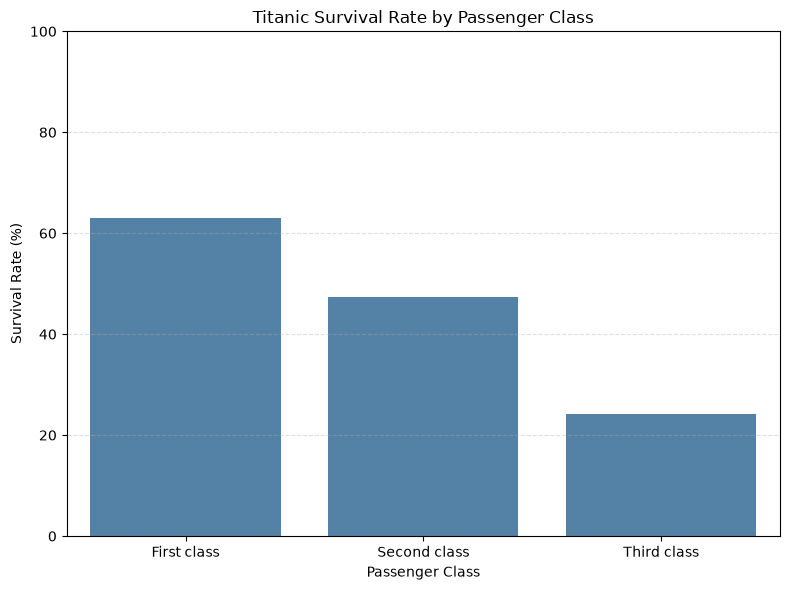

In [29]:
# Create a bar chart showing survival rate by passenger class.
plt.figure(figsize=(8, 6))

sns.barplot(
    data=survival_by_class,
    x="Pclass",
    y="Survival_Rate_Percent",
    color="steelblue"
)

plt.title("Titanic Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(
    ticks=[0, 1, 2],
    labels=["First class", "Second class", "Third class"]
)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Survival and Gender

To investigate whether survival is associated with gender, we compare the
survival rates of female and male passengers.

Because `Survived` contains 0 and 1 values, its mean within each gender is the
proportion of passengers who survived.

In [30]:
# Group passengers by gender and calculate survival statistics.
survival_by_gender = (
    df.groupby("Sex")["Survived"]
    .agg(
        Passengers="count",
        Survivors="sum",
        Survival_Rate="mean"
    )
    .reset_index()
)

# Calculate the number of passengers who did not survive.
survival_by_gender["Did_Not_Survive"] = (
    survival_by_gender["Passengers"]
    - survival_by_gender["Survivors"]
)

# Convert the survival proportions into percentages.
survival_by_gender["Survival_Rate_Percent"] = (
    survival_by_gender["Survival_Rate"] * 100
)

display(
    survival_by_gender[
        [
            "Sex",
            "Passengers",
            "Survivors",
            "Did_Not_Survive",
            "Survival_Rate_Percent"
        ]
    ].round(2)
)

,Sex,Passengers,Survivors,Did_Not_Survive,Survival_Rate_Percent
0,female,314,233,81,74.20
1,male,577,109,468,18.89


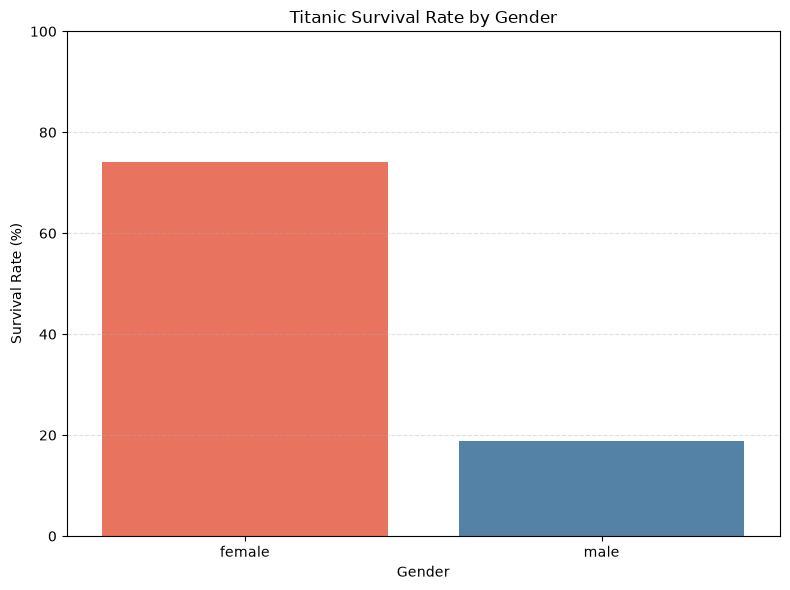

In [31]:
# Create a survival-rate bar chart by gender.
plt.figure(figsize=(8, 6))

sns.barplot(
    data=survival_by_gender,
    x="Sex",
    y="Survival_Rate_Percent",
    hue="Sex",
    palette={
        "female": "tomato",
        "male": "steelblue"
    },
    legend=False
)

plt.title("Titanic Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Problems With Using Every Column Without Preparation

Using every Titanic dataset column without preparation could cause several
problems:

1. **Missing values**

   `Age`, `Cabin`, and `Embarked` contain missing values. Neural networks cannot
   normally train correctly with empty or `NaN` values.

2. **Text values**

   Columns such as `Sex`, `Embarked`, `Name`, `Ticket`, and `Cabin` contain
   text. Neural networks require numerical inputs, so useful categorical
   variables must be encoded.

3. **Different numerical scales**

   Variables such as `Pclass`, `Age`, and `Fare` use very different numerical
   ranges. Numerical features should be scaled so that large values do not
   dominate the training process simply because of their size.

4. **Unhelpful identifiers**

   `PassengerId` is mainly a unique row identifier. It may introduce accidental
   patterns that do not apply to new passengers.

5. **High-cardinality variables**

   `Name`, `Ticket`, and `Cabin` contain many unique values. Encoding every
   unique value could create hundreds of additional features and increase the
   risk of overfitting.

6. **Feature engineering requirements**

   Some columns may contain useful information, but not in their original
   format. For example, a title such as `Mr`, `Mrs`, `Miss`, or `Master` could
   be extracted from `Name`. A deck letter could be extracted from `Cabin`.

7. **Data leakage**

   `Survived` is the target variable. Including it among the input features
   would give the model the correct answer during training and create
   unrealistically high performance.

8. **Overfitting**

   Using too many irrelevant or nearly unique columns may cause the model to
   memorise the training passengers instead of learning patterns that work on
   unseen passengers.

9. **Inconsistent training and testing data**

   Categories may differ between the training and test datasets. The same
   preprocessing rules must therefore be applied to both datasets.

### Preparation Used in This Exercise

- Missing numerical values are replaced with the median.
- Missing categorical values are replaced with the most frequent category.
- Categorical variables are converted using one-hot encoding.
- Numerical variables are standardised.
- The `Survived` target is kept separate from the input features.
- Columns that require additional feature engineering are excluded initially.

Therefore, the data must be cleaned, encoded, scaled, and divided into features
and a target before it can be supplied to the neural network.

## Logistic Regression Coefficients

A logistic regression classifier is trained so that we can inspect how each
prepared feature is associated with survival.

A positive coefficient increases the model's estimated log-odds of survival.
A negative coefficient decreases the estimated log-odds of survival.

The coefficients must be interpreted carefully because numerical variables
were standardised and categorical variables were one-hot encoded.

In [35]:
# Import the logistic regression classifier.
from sklearn.linear_model import LogisticRegression

# Import NumPy for converting coefficients into odds ratios.
import numpy as np

# Create the logistic regression classifier.
#
# max_iter=1000 gives the algorithm enough iterations to converge.
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the same prepared training data
# that was supplied to the neural network.
logistic_model.fit(
    X_train_prepared,
    y_train
)

# Calculate test accuracy.
logistic_test_accuracy = logistic_model.score(
    X_test_prepared,
    y_test
)

print(
    "Logistic regression test accuracy:",
    f"{logistic_test_accuracy:.2%}"
)

Logistic regression test accuracy: 80.45%


In [36]:
# Get the names produced by the preprocessing pipeline.
#
# These include the numerical columns and the one-hot encoded
# versions of Sex and Embarked.
prepared_feature_names = (
    preprocessor.get_feature_names_out()
)

# Extract the model coefficients.
coefficients = logistic_model.coef_[0]

# Create a table connecting each feature to its coefficient.
coefficient_table = pd.DataFrame({
    "Feature": prepared_feature_names,
    "Coefficient": coefficients
})

# Convert coefficients into odds ratios.
#
# An odds ratio above 1 is associated with increased survival odds.
# An odds ratio below 1 is associated with decreased survival odds.
coefficient_table["Odds_Ratio"] = np.exp(
    coefficient_table["Coefficient"]
)

# Sort from the strongest positive coefficient
# to the strongest negative coefficient.
coefficient_table = coefficient_table.sort_values(
    by="Coefficient",
    ascending=False
).reset_index(drop=True)

display(coefficient_table.round(4))

,Feature,Coefficient,Odds_Ratio
0,categories__Sex_female,1.2994,3.6673
1,categories__Embarked_Q,0.3048,1.3563
2,numbers__Fare,0.1003,1.1055
3,categories__Embarked_C,0.0322,1.0328
4,numbers__Parch,-0.0664,0.9357
5,numbers__SibSp,-0.2606,0.7706
6,categories__Embarked_S,-0.3583,0.6989
7,numbers__Age,-0.5028,0.6048
8,numbers__Pclass,-0.9220,0.3977
9,categories__Sex_male,-1.3207,0.2669


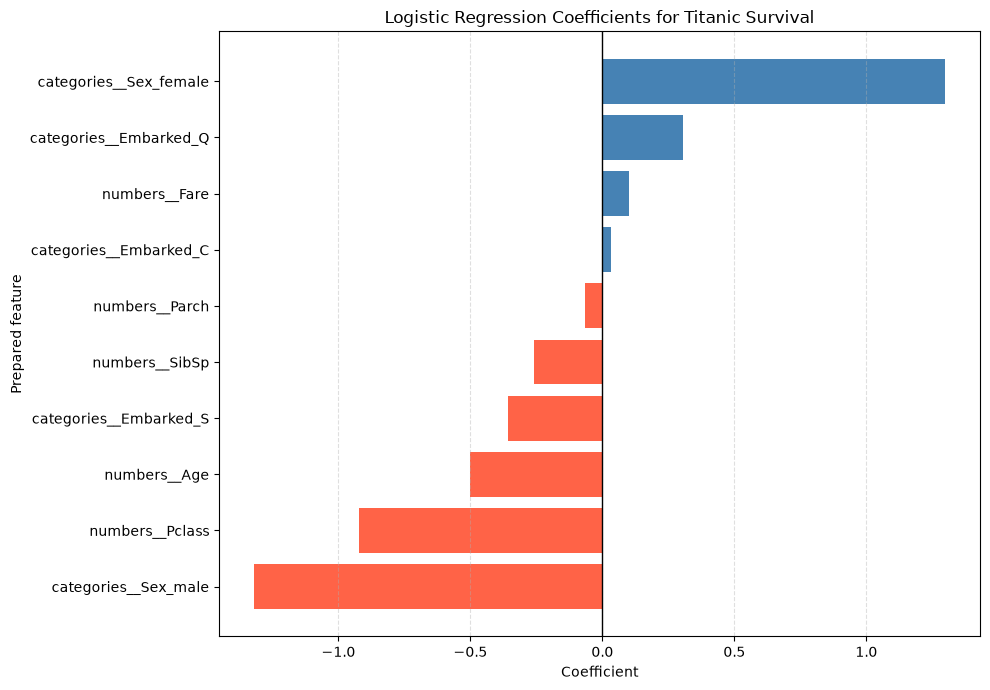

In [37]:
# Create colours based on coefficient direction.
coefficient_colours = [
    "steelblue" if value > 0 else "tomato"
    for value in coefficient_table["Coefficient"]
]

plt.figure(figsize=(10, 7))

plt.barh(
    coefficient_table["Feature"],
    coefficient_table["Coefficient"],
    color=coefficient_colours
)

# Add a vertical line representing a coefficient of zero.
plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.title("Logistic Regression Coefficients for Titanic Survival")
plt.xlabel("Coefficient")
plt.ylabel("Prepared feature")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Interpretation of the Coefficients

A positive coefficient means that the feature is associated with a higher
estimated probability of survival, while the other model features are held
constant.

A negative coefficient means that the feature is associated with a lower
estimated probability of survival.

The one-hot encoded gender variables are expected to show that being female is
associated with higher estimated survival, while being male is associated with
lower estimated survival. This agrees with the earlier finding that female
passengers had a much higher survival rate.

`Pclass` is expected to have a negative coefficient. Because higher class
numbers represent lower ticket classes, moving from first class toward third
class is associated with lower estimated survival.

`Age` may have a negative coefficient, suggesting that increased age is
associated with lower estimated survival after the other model variables are
considered.

`Fare` may have a positive coefficient. Passengers paying higher fares may
have had higher estimated survival, although fare is also related to passenger
class.

The coefficients for `SibSp` and `Parch` describe how family-related passenger
counts are associated with survival after the other variables have been
considered.

The embarkation coefficients describe differences associated with the
one-hot encoded embarkation categories. These differences should not be
treated as proof that the embarkation port caused survival.

### Interpretation Limitations

The numerical features were standardised. Therefore, a numerical coefficient
represents the effect of approximately one standard-deviation increase, not a
one-unit increase in the original measurement.

All categories were one-hot encoded. Because both sides of a category may be
present, such as `Sex_female` and `Sex_male`, their individual coefficients
should be interpreted carefully. Comparing their signs and relative sizes is
more useful than treating either coefficient as an isolated causal effect.

The coefficients show associations learned by the model. They do not prove
that any feature caused a passenger to survive. Passenger class, fare, gender
and other variables may also be related to one another.

## Training the Logistic Regression Model

Logistic regression is a binary classification algorithm despite its name.

The model learns the relationship between the prepared passenger features and
the binary `Survived` target.

The prepared features are used because missing values have been filled,
categorical variables have been one-hot encoded, and numerical variables have
been standardised.

In [38]:
# Import the logistic regression classifier.
from sklearn.linear_model import LogisticRegression

# Create the logistic regression model.
#
# max_iter=1000 gives the algorithm enough attempts to find
# coefficients that minimise the classification error.
#
# random_state=42 helps make the results reproducible.
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model.
#
# X_train_prepared contains the cleaned, encoded and scaled features.
# y_train contains the correct survival classifications.
logistic_model.fit(
    X_train_prepared,
    y_train
)

print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


In [39]:
# Calculate the model's accuracy on the training data.
training_accuracy = logistic_model.score(
    X_train_prepared,
    y_train
)

# Calculate accuracy on passengers the model did not see during training.
testing_accuracy = logistic_model.score(
    X_test_prepared,
    y_test
)

print(
    "Training accuracy:",
    f"{training_accuracy:.2%}"
)

print(
    "Testing accuracy:",
    f"{testing_accuracy:.2%}"
)

Training accuracy: 80.76%
Testing accuracy: 80.45%
